<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Preparación de los datos del Spanish Fake News Corpus</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

Este notebook aplica las decisiones del análisis exploratorio (`analisis_exploratorio.ipynb`, Sección 18): deduplica, normaliza el texto igual en ambas versiones, enmascara el medio, calcula rasgos de estilo y arma los folds agrupados. **Solo lee** `data/*.xlsx` (no los modifica) y escribe `data/processed/corpus.parquet` (train + development), `data/processed/test.parquet` (solo para `evaluacion.ipynb`), `data/processed/lexico_medios.csv` y `resultados/folds.csv`.

## Contenido

    * [Sección 0: Configuración](#seccion-0)
* **[Metodología CRISP-DM: Preparación de los datos](#fase-preparacion)**
    * [Sección 1: Selección de los datos](#seccion-1)
    * [Sección 2: Limpieza: duplicados y fuga](#seccion-2)
    * [Sección 3: Limpieza: normalización del texto](#seccion-3)
    * [Sección 4: Construcción: enmascarado del medio](#seccion-4)
    * [Sección 5: Construcción: rasgos de estilo y banderas de análisis](#seccion-5)
    * [Sección 6: Particiones y protocolo de validación](#seccion-6)
    * [Sección 7: Formato y guardado](#seccion-7)
    * [Sección 8: Perfilado antes y después](#seccion-8)
    * [Sección 9: Bitácora de calidad](#seccion-9)
* **[Conclusiones](#conclusiones)**
    * [Sección 10: Resumen por sección](#seccion-10)
    * [Sección 11: Implicaciones para el modelado](#seccion-11)
    * [Sección 12: Referencias](#seccion-12)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Configuración</span></div>

> **Qué se hace:** cargamos bibliotecas, constantes y rutas.
>
> **Qué se espera ver:** el entorno `fakedes` y las carpetas de salida creadas.

### 0.1 Bibliotecas

In [1]:
# Manejo de datos
import os
import re
import sys
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Similitud de textos y particiones
from rapidfuzz import fuzz
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

# Palabras vacías
import stopwordsiso as sw

# Funciones compartidas del proyecto
import utils_fakedes as uf
from utils_fakedes import guardar, guardar_csv

### 0.2 Constantes

In [2]:
SEMILLA = uf.SEMILLA                      # 42, definida en utils_fakedes.py
COLORES_CLASE = uf.COLORES_CLASE
TINTA, TINTA_SUAVE = uf.TINTA, uf.TINTA_SUAVE
N_FOLDS = 5
UMBRAL_CASI_DUPLICADO = 0.8               # el mismo del análisis exploratorio (Sección 12.1)
UMBRAL_PAR = 0.3                          # el mismo del análisis exploratorio (Sección 12.3)
MAX_DF_OTRAS_FUENTES = 0.02               # un nombre de medio se enmascara si aparece en ≤ 2 % de las noticias de otras fuentes
STOPWORDS_ES = set(sw.stopwords('es'))
uf.configurar_graficas()

### 0.3 Rutas y carpetas de salida

**Tabla 0.3.** Archivos que lee y escribe el notebook.

In [3]:
uf.crear_carpetas(uf.RUTA_PROCESADOS, uf.RUTA_RESULTADOS, uf.RUTA_FIGURAS)
pd.DataFrame({'archivo': ['data/*.xlsx', 'data/processed/corpus.parquet', 'data/processed/test.parquet',
                          'data/processed/lexico_medios.csv', 'resultados/folds.csv'],
              'uso': ['lectura (originales, no se modifican)', 'train + development preparados (modelado)',
                      'test preparado (solo evaluacion.ipynb)', 'nombres de medios a enmascarar', 'asignación de folds']})

,archivo,uso
0,data/*.xlsx,"lectura (originales, no se modifican)"
1,data/processed/corpus.parquet,train + development preparados (modelado)
2,data/processed/test.parquet,test preparado (solo evaluacion.ipynb)
3,data/processed/lexico_medios.csv,nombres de medios a enmascarar
4,resultados/folds.csv,asignación de folds


<a id="fase-preparacion"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Preparación de los datos</span></div>

<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: Selección de los datos</span></div>

> **Qué se hace:** cargamos el corpus homogeneizado y fijamos qué columnas son entrada y cuáles solo sirven para agrupar o analizar.
>
> **Qué se espera ver:** 1,543 noticias; solo `Headline` y `Text` como entrada.

**Tabla 1.1.** Rol de cada columna en el modelado (decidido en el análisis exploratorio, Secciones 5, 8 y 14).

| Columna | Rol | Motivo |
|:--|:--|:--|
| `Headline`, `Text` | **Entrada** | Únicas columnas disponibles para una noticia nueva |
| `Category` | Etiqueta | `Fake` es la clase positiva |
| `Source` | Grupo de los folds; análisis | V de Cramér con la clase = 0.996 en train: atajo |
| `Topic` | Análisis (*leave-one-topic-out*, errores por tema) | Lo asigna la fuente; no está en una noticia nueva |
| `Link`, `Id` | Análisis | El formato del enlace delata la clase (40 enlaces "Perma" en falsas de test) |

Usamos `uf.cargar_corpus()`, que reproduce la homogeneización del análisis exploratorio (Sección 4). **Tabla 1.2.** Noticias por partición y clase al cargar.

In [4]:
crudo = uf.cargar_corpus()
crudo['id_unico'] = crudo['particion'].str[:3] + '_' + crudo['Id'].astype(str)
crudo['fuente'] = uf.normalizar_fuente(crudo['Source'])
crudo['dominio'] = crudo['Link'].str.extract(r'https?://(?:www\.)?([^/\s]+)', expand = False)
pd.crosstab(crudo['particion'], crudo['Category'], margins = True).reindex(['train', 'development', 'test', 'All'])

Category,Fake,True,All
particion,,,
train,338,338,676
development,142,153,295
test,286,286,572
All,766,777,1543


Los `Id` se repiten entre particiones (los 295 de `development` existen en `train`), así que creamos `id_unico` con un prefijo de la partición. **Tabla 1.3.** Identificadores repetidos.

In [5]:
pd.DataFrame({'identificador': ['Id', 'id_unico'],
              'valores repetidos en el corpus': [int(crudo['Id'].duplicated().sum()), int(crudo['id_unico'].duplicated().sum())],
              'resultado': ['se reemplaza por id_unico', '✅' if not crudo['id_unico'].duplicated().any() else '❌']})

,identificador,valores repetidos en el corpus,resultado
0,Id,867,se reemplaza por id_unico
1,id_unico,0,✅


<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: Limpieza: duplicados y fuga</span></div>

> **Qué se hace:** detectamos de nuevo los casi duplicados y aplicamos la regla de eliminación.
>
> **Qué se espera ver:** las mismas 11 parejas del análisis exploratorio y 10 noticias eliminadas de `train` + `development`.

⚠️ El test no se modifica: solo se eliminan copias de `train` o `development`. Para encontrar las copias de noticias del test hay que comparar con el test; eso no usa sus etiquetas ni ajusta nada del modelo.

### 2.1 Regla de eliminación

* **`train` ↔ `test`:** se elimina la copia de `train` (fuga hacia la evaluación final).
* **`train` ↔ `development`:** se elimina la copia de `development` (las dos quedarían en el mismo conjunto de CV y una de ellas sobraría).
* **Dentro de `development`:** se elimina la de `Id` mayor.
* **Dentro de `test`:** no se toca nada.

Se descartó conservar los duplicados con una bandera: en CV agrupada, dos copias de la misma noticia en folds distintos inflarían el puntaje.

**Tabla 2.1.** Pares con coseno TF-IDF ≥ 0.8 y la copia que se elimina.

In [6]:
textos_comparables = (crudo['Headline'].fillna('') + ' ' + crudo['Text']).str.replace(r'\*[A-Z]+\*', ' ', regex = True)
similitud = cosine_similarity(TfidfVectorizer(sublinear_tf = True).fit_transform(textos_comparables))
a, b = np.where(np.triu(similitud, k = 1) >= UMBRAL_CASI_DUPLICADO)

def copia_a_eliminar(i, j):
    '''
    Función que decide qué copia de un par de casi duplicados se elimina

    inputs:
    --------
        i (int): Posición de la primera noticia en crudo
        j (int): Posición de la segunda noticia en crudo

    outputs:
    --------
        str o None: id_unico de la copia que se elimina (None si ambas están en test)
    '''
    pi, pj = crudo['particion'].iat[i], crudo['particion'].iat[j]
    prioridad = {'test': 0, 'train': 1, 'development': 2}
    if pi == pj == 'test':
        return None
    if pi == pj:
        return crudo['id_unico'].iat[i] if crudo['Id'].iat[i] > crudo['Id'].iat[j] else crudo['id_unico'].iat[j]
    return crudo['id_unico'].iat[j] if prioridad[pj] > prioridad[pi] else crudo['id_unico'].iat[i]

pares_dup = pd.DataFrame({'id_a': crudo['id_unico'].values[a], 'id_b': crudo['id_unico'].values[b],
                          'clase_a': crudo['Category'].values[a], 'clase_b': crudo['Category'].values[b],
                          'coseno': similitud[a, b].round(3), 'se elimina': [copia_a_eliminar(i, j) for i, j in zip(a, b)]})
pares_dup.sort_values('coseno', ascending = False)

,id_a,id_b,clase_a,clase_b,coseno,se elimina
9,dev_129,dev_147,Fake,Fake,1.000,dev_147
1,tra_54,tes_345,Fake,Fake,0.996,tra_54
4,tra_252,dev_19,Fake,Fake,0.989,dev_19
0,tra_12,tes_433,Fake,Fake,0.986,tra_12
7,tra_514,dev_225,True,True,0.983,dev_225
3,tra_172,dev_177,True,True,0.982,dev_177
8,tra_608,tes_427,True,True,0.977,tra_608
6,tra_462,dev_267,True,True,0.977,dev_267
2,tra_101,tes_187,Fake,Fake,0.971,tra_101
5,tra_278,dev_65,Fake,Fake,0.965,dev_65


**Tabla 2.2.** Tamaño antes y después de eliminar, por partición y clase.

In [7]:
eliminados = set(pares_dup['se elimina'].dropna())
dedup = crudo[~crudo['id_unico'].isin(eliminados)].reset_index(drop = True)
antes_despues = pd.concat({'antes': pd.crosstab(crudo['particion'], crudo['Category']),
                           'después': pd.crosstab(dedup['particion'], dedup['Category'])}, axis = 1).reindex(['train', 'development', 'test'])
antes_despues

antes      después     
Category     Fake True    Fake True
particion                          
train         338  338     335  337
development   142  153     139  150
test          286  286     286  286

**Qué se observa.** Se eliminan 10 noticias, todas con la misma clase que su copia. En `train` se quitan 4 (3 falsas y 1 verdadera), las copias de noticias del test. En `development` se quitan 6 (3 y 3): 5 copias de noticias de `train` y el duplicado interno. `train` + `development` pasa de 971 a 961 noticias, con 49.4 % y 49.3 % de falsas antes y después. El par 109 / 353 del test (clases distintas) se conserva. **La deduplicación no cambia el balance de clases y elimina toda la fuga entre particiones (Tabla 8.1).**

<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: Limpieza: normalización del texto</span></div>

> **Qué se hace:** aplicamos a ambas versiones las mismas reglas: espacios, titular repetido al inicio, anonimización y titular vacío.
>
> **Qué se espera ver:** que el texto de la versión 2.0 quede con el formato de la 1.0 y que cada regla cambie un número conocido de textos.

⚠️ No se baja a minúsculas, no se quita puntuación ni palabras vacías: el estilo puede ser señal (análisis exploratorio, Sección 10) y esas decisiones se prueban en el modelado.

Cada regla se aplica en orden y contamos cuántos textos cambia. Las funciones están en `utils_fakedes.py` y son las mismas que usará la API (`preparar_noticia`).

**Tabla 3.1.** Textos que cambia cada regla, por versión.

In [8]:
prep = dedup.copy()
prep['sin_titular_original'] = prep['Headline'].isna()
titular0, texto0 = prep['Headline'].fillna(''), prep['Text']

titular1, texto1 = titular0.map(uf.normalizar_espacios), texto0.map(uf.normalizar_espacios)
texto2 = pd.Series([uf.quitar_titular_inicial(t, x) for t, x in zip(titular1, texto1)], index = prep.index)
titular3, texto3 = titular1.map(uf.anonimizar_como_v1), texto2.map(uf.anonimizar_como_v1)

cambios = pd.DataFrame({'3.1 espacios': (titular1 != titular0) | (texto1 != texto0),
                        '3.2 titular repetido al inicio': texto2 != texto1,
                        '3.3 anonimización (números y URLs)': (titular3 != titular1) | (texto3 != texto2),
                        '3.4 titular vacío → cadena vacía': prep['sin_titular_original']})
tabla_cambios = cambios.groupby(prep['version']).sum().T
tabla_cambios['% del total'] = (100 * tabla_cambios.sum(axis = 1) / len(prep)).round(1)
prep['titular'], prep['texto'] = titular3, texto3
tabla_cambios

version,1.0,2.0,% del total
3.1 espacios,64,274,22.0
3.2 titular repetido al inicio,936,1,61.1
3.3 anonimización (números y URLs),3,496,32.6
3.4 titular vacío → cadena vacía,0,72,4.7


**Qué se observa.** La regla que más textos cambia es la del titular repetido: 936 textos de la 1.0 y 1 de la 2.0 (61.1 % del corpus). La anonimización cambia 496 textos de la 2.0 y 3 de la 1.0, que tenían números que se escaparon de la anonimización original. La normalización de espacios cambia 64 textos de la 1.0 y 274 de la 2.0; los 72 titulares vacíos son todos del test. **Las reglas actúan sobre todo en una de las dos versiones; su objetivo es quitar las diferencias de formato que un modelo usaría para distinguir versiones en lugar de clases.**

**Decisiones de esta sección:**

* **3.2 Titular repetido.** Se elimina solo si el texto empieza exactamente con el titular (sin distinguir mayúsculas). Los textos que lo repiten con variaciones se dejan igual: recortarlos exigiría una regla difusa que podría borrar parte del cuerpo.
* **3.3 Anonimización.** Se lleva la versión 2.0 al formato de la 1.0 y no al revés: los números originales de la 1.0 ya no existen. Los dígitos pegados a letras (`CR7`, `5G`) y los sufijos con guion (`COVID-19`) se conservan, como en la 1.0.
* **3.4 Titular vacío.** Se rellena con la cadena vacía, que es neutra para TF-IDF (no aporta términos). Se descartó "sin titular" porque introduce palabras que nunca aparecen en train. La bandera `sin_titular_original` se guarda solo para analizar errores, no como entrada.

**Tabla 3.2.** Verificación de las reglas, esperado frente a obtenido. La regla de números es la misma `uf.PATRON_NUMERO` que aplica la anonimización.

In [9]:
verif = pd.DataFrame([
    ('ningún texto con espacios repetidos', 0, int(prep['texto'].str.contains(r'[ \t]{2,}').sum())),
    ('ningún texto con espacio duro o de ancho cero', 0, int(prep['texto'].str.contains('[ ​‌‍﻿]').sum())),
    ('textos de test con números sueltos sin anonimizar (misma regla)', 0, int(prep.loc[prep['version'] == '2.0', 'texto'].map(lambda t: bool(uf.PATRON_NUMERO.search(t))).sum())),
    ('textos de test con URL visible', 0, int(prep.loc[prep['version'] == '2.0', 'texto'].str.contains(r'https?://|www\.').sum())),
    ('textos vacíos después de preparar', 0, int(prep['texto'].str.strip().eq('').sum())),
], columns = ['verificación', 'esperado', 'obtenido'])
verif['resultado'] = np.where(verif['esperado'] == verif['obtenido'], '✅', '❌')
verif

,verificación,esperado,obtenido,resultado
0,ningún texto con espacios repetidos,0,0,✅
1,ningún texto con espacio duro o de ancho cero,0,0,✅
2,textos de test con números sueltos sin anonimi...,0,0,✅
3,textos de test con URL visible,0,0,✅
4,textos vacíos después de preparar,0,0,✅


**Qué se observa.** Las 5 verificaciones pasan (5 de 5 ✅): no quedan espacios repetidos, espacios duros, números sueltos ni URLs en el test, y ningún texto quedó vacío. Los dígitos que se conservan en el test (Tabla 3.3) son sufijos de nombres como *COVID-19* (490 ocurrencias en sus tres escrituras), *SARS-CoV-2* y *5G*, que en la 1.0 tampoco se anonimizaban. **El texto de ambas versiones queda con el mismo formato.**

**Tabla 3.3.** Dígitos que se conservan a propósito en el test (pegados a letras o tras letra + guion), las 10 formas más frecuentes.

In [10]:
conservados = prep.loc[prep['version'] == '2.0', 'texto'].str.findall(r'\S*\d\S*').explode().dropna()
conservados.str.strip('.,;:()"').str.replace(r'\d+', '9', regex = True).value_counts().head(10).rename('ocurrencias').to_frame()

,ocurrencias
texto,
COVID-9,208
Covid-9,144
covid-9,138
9G,87
SARS-CoV-9,59
9º,24
Sars-Cov-9,11
CO9,11
N9,7


<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: Construcción: enmascarado del medio</span></div>

> **Qué se hace:** armamos un léxico de nombres de medios con las fuentes y dominios de `train` + `development` y los borramos en una segunda versión del texto (`titular_sin_medio`, `texto_sin_medio`).
>
> **Qué se espera ver:** cuántas noticias mencionan un medio del léxico por clase; en la versión enmascarada esas menciones desaparecen.

⚠️ El léxico se construye solo con `train` + `development`. Los medios del test que no aparecen en train no se enmascaran, igual que pasaría con una noticia nueva.

### 4.1 Léxico de medios (Tabla 4.1)

Candidatos: el nombre normalizado de cada fuente y el nombre del dominio sin `www` ni terminación (por ejemplo, `eluniversal`), de 4 caracteres o más. Algunos nombres son palabras comunes (por ejemplo, un periódico llamado "Proceso"); enmascararlos borraría vocabulario normal. Por eso **solo se enmascara un nombre si aparece en ≤ 2 % de las noticias de otras fuentes** (`MAX_DF_OTRAS_FUENTES`).

**Tabla 4.1.** Candidatos incluidos y excluidos del léxico.

In [11]:
v1 = prep[prep['version'] == '1.0']
texto_v1 = (v1['titular'] + ' ' + v1['texto']).str.lower()
nombre_dom = v1['dominio'].str.lower().str.replace(r'\.(com|net|org|es|mx|co|info|news|pe|ar|cl|ec)(\.[a-z]{2})?$', '', regex = True).str.split('.').str[-1]
candidatos = pd.concat([pd.DataFrame({'nombre': v1['fuente'], 'fuente': v1['fuente'], 'origen': 'fuente'}),
                        pd.DataFrame({'nombre': nombre_dom, 'fuente': v1['fuente'], 'origen': 'dominio'})]).dropna()
candidatos = candidatos[candidatos['nombre'].str.len() >= 4].drop_duplicates('nombre')

def df_otras_fuentes(nombre, fuente):
    '''
    Función que calcula la proporción de noticias de otras fuentes que contienen un nombre

    inputs:
    --------
        nombre (str): Nombre candidato en minúsculas
        fuente (str): Fuente a la que pertenece el nombre

    outputs:
    --------
        float: Proporción de noticias de otras fuentes de la versión 1.0 que lo mencionan
    '''
    otras = texto_v1[v1['fuente'] != fuente]
    return otras.str.contains(r'(?<!\w)' + re.escape(nombre) + r'(?!\w)', regex = True).mean()

candidatos['df otras fuentes'] = [df_otras_fuentes(n, f) for n, f in zip(candidatos['nombre'], candidatos['fuente'])]
candidatos['incluido'] = candidatos['df otras fuentes'] <= MAX_DF_OTRAS_FUENTES
candidatos[['nombre', 'fuente', 'origen', 'df otras fuentes', 'incluido']].to_csv(os.path.join(uf.RUTA_PROCESADOS, 'lexico_medios.csv'), index = False, encoding = 'utf-8')
candidatos.groupby(['origen', 'incluido']).size().unstack(fill_value = 0)

incluido,False,True
origen,,
dominio,3,86
fuente,10,136


**Tabla 4.2.** Nombres excluidos por ser comunes en otras fuentes (los 10 con mayor frecuencia).

In [12]:
candidatos.loc[~candidatos['incluido'], ['nombre', 'origen', 'df otras fuentes']].sort_values('df otras fuentes', ascending = False).head(10).round(3)

,nombre,origen,df otras fuentes
61,quien,fuente,0.276
874,sin embargo,fuente,0.192
104,tiempo,fuente,0.178
8,el país,fuente,0.117
607,el mundo,fuente,0.098
31,proceso,fuente,0.078
468,twitter,fuente,0.060
105,facebook,dominio,0.052
414,televisa,dominio,0.046
72,marca,fuente,0.037


**Qué se observa.** De 235 candidatos (146 nombres de fuente y 89 de dominio), se incluyen 222 en el léxico y se excluyen 13 por ser frecuentes en otras fuentes. Algunos son palabras comunes que también son nombres de medios (*quien*, en el 27.6 % de las noticias de otras fuentes; *sin embargo*, *tiempo*, *proceso*, *marca*). Otros son plataformas que se mencionan como tema (*twitter*, *facebook*, *televisa*). ⚠️ También quedan fuera *el país* (11.7 %) y *el mundo* (9.8 %), que son expresiones comunes además de periódicos; sus menciones como medio no se borran. **El umbral evita borrar vocabulario normal, a costa de dejar algunas menciones de dos medios grandes de verdaderas.**

### 4.2 Borrar en lugar de marcar (Tabla 4.3)

El prompt sugería reemplazar el nombre por `<MEDIO>`. Lo descartamos por dos razones: (1) el marcador conserva la señal "menciona un medio conocido", que es justamente el atajo; (2) el tokenizador por defecto de `TfidfVectorizer` convierte `<MEDIO>` en la palabra común "medio" y la mezcla con su uso normal. **Borramos los nombres** (la constante `uf.MARCA_MEDIO` queda disponible si se quiere probar el marcador).

**Tabla 4.3.** Noticias que mencionan algún medio del léxico (antes de borrar) y menciones que quedan después de borrar, por versión y clase.

In [13]:
lexico = candidatos.loc[candidatos['incluido'], 'nombre'].tolist()
patron = uf.patron_medios(lexico)
prep['menciona_medio'] = (prep['titular'] + ' ' + prep['texto']).map(lambda t: patron.search(t) is not None)
prep['titular_sin_medio'] = prep['titular'].map(lambda t: uf.enmascarar_medios(t, patron))
prep['texto_sin_medio'] = prep['texto'].map(lambda t: uf.enmascarar_medios(t, patron))
quedan = (prep['titular_sin_medio'] + ' ' + prep['texto_sin_medio']).map(lambda t: patron.search(t) is not None)
efecto = prep.groupby(['version', 'Category'])['menciona_medio'].agg(['size', 'sum', 'mean'])
efecto.columns = ['noticias', 'mencionan un medio', '%']
efecto['%'] = (100 * efecto['%']).round(1)
efecto['quedan después de borrar'] = quedan.groupby([prep['version'], prep['Category']]).sum()
efecto

noticias  mencionan un medio     %  quedan después de borrar
version Category                                                              
1.0     Fake           474                  39   8.2                         0
        True           487                 105  21.6                         0
2.0     Fake           286                  32  11.2                         0
        True           286                  40  14.0                         0

**Qué se observa.** En la versión 1.0, el 21.6 % de las verdaderas (105) menciona algún medio del léxico, contra el 8.2 % de las falsas (39). En la 2.0 la diferencia es menor: 14.0 % (40) contra 11.2 % (32). Estas cifras son más altas que las de la Sección 14 del EDA porque ahora cuenta cualquier medio del léxico, no solo el propio. Después de borrar no queda ninguna mención (0 en los cuatro grupos). **En el modelado comparamos `texto` contra `texto_sin_medio`: si el puntaje de CV cae al borrar los medios, el modelo los estaba usando como atajo.**

<a id="seccion-5"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 5: Construcción: rasgos de estilo y banderas de análisis</span></div>

> **Qué se hace:** calculamos 10 rasgos de estilo por noticia (para el modelo de árboles) y las banderas que usaremos para analizar errores.
>
> **Qué se espera ver:** rasgos sin valores faltantes, calculados solo con el texto (no con el titular).

#### Glosario de la sección
* **Rasgo de estilo:** medida de la forma del texto (longitud, signos, mayúsculas) que no depende de qué palabras se usan.
* **Bandera de análisis:** columna que sirve para separar resultados (por ejemplo, publicaciones de redes) y nunca entra al modelo.

Los rasgos se calculan por fila con reglas fijas (no aprenden de los datos), así que no generan fuga; **el escalado sí aprende y se hace dentro del `Pipeline` de cada fold** en el modelado. No usamos rasgos del titular: los 72 titulares vacíos del test darían un valor que nunca aparece en train y la diferencia de longitud del titular no fue significativa en test (análisis exploratorio, Tabla 9.3). La longitud va en logaritmo porque está sesgada a la derecha.

**Tabla 5.1.** Definición de los rasgos (`uf.rasgos_estilo`).

| Rasgo | Definición |
|:--|:--|
| `est_log_palabras` | log(1 + número de palabras) |
| `est_palabras_por_oracion` | palabras / oraciones |
| `est_long_media_palabra` | longitud media de palabra en caracteres |
| `est_prop_mayusculas` | letras mayúsculas / letras |
| `est_prop_palabras_mayusculas` | palabras de 3+ letras escritas en mayúsculas / palabras |
| `est_exclamaciones`, `est_interrogaciones`, `est_comillas` | signos por cada 1,000 caracteres |
| `est_numeros` | marcas `*NUMBER*` por cada 100 palabras |
| `est_prop_vacias` | palabras vacías del español / palabras |

**Tabla 5.2.** Mediana de cada rasgo por versión y clase.

In [14]:
rasgos = pd.DataFrame([uf.rasgos_estilo(t, STOPWORDS_ES) for t in prep['texto']], index = prep.index)
prep = pd.concat([prep, rasgos], axis = 1)
prep.groupby(['version', 'Category'])[uf.RASGOS_ESTILO].median().T.round(3)

version                          1.0             2.0        
Category                        Fake    True    Fake    True
est_log_palabras               5.557   5.911   5.700   6.292
est_palabras_por_oracion      32.618  29.111  24.921  27.766
est_long_media_palabra         4.781   4.885   4.946   5.012
est_prop_mayusculas            0.027   0.034   0.029   0.026
est_prop_palabras_mayusculas   0.003   0.004   0.005   0.004
est_exclamaciones              0.000   0.000   0.000   0.000
est_interrogaciones            0.000   0.000   0.000   0.000
est_comillas                   3.367   2.590   2.221   2.760
est_numeros                    0.436   1.217   0.895   1.177
est_prop_vacias                0.585   0.560   0.569   0.565

**Tabla 5.3.** Banderas de análisis por partición y clase (conteos).

In [15]:
verificadores = ['afpfactual', 'maldita', 'colombia check', 'colombiacheck', 'ecuador chequea', 'ecuadorchequea',
                 'chequeado', 'verificado', 'agencia efe', 'facebook']
prep['fuente_verificador'] = prep['fuente'].isin(verificadores)
prep['texto_corto'] = prep['texto'].str.split().str.len() < 60
banderas = ['sin_titular_original', 'fuente_verificador', 'texto_corto', 'menciona_medio']
tabla_banderas = prep.groupby(['particion', 'Category'], sort = False)[banderas].sum()
tabla_banderas['rasgos con faltantes'] = prep[uf.RASGOS_ESTILO].isna().any(axis = 1).groupby([prep['particion'], prep['Category']], sort = False).sum()
tabla_banderas

sin_titular_original  fuente_verificador  texto_corto  \
particion   Category                                                          
train       Fake                         0                   0            8   
            True                         0                   0            1   
development Fake                         0                   0            1   
            True                         0                   0            1   
test        True                         0                   1            0   
            Fake                        72                 117            4   

                      menciona_medio  rasgos con faltantes  
particion   Category                                        
train       Fake                  26                     0  
            True                  76                     0  
development Fake                  13                     0  
            True                  29                     0  
test        True                  40                     0  
            Fake                  32                     0

**Qué se observa.** Ningún rasgo tiene faltantes (0 en todas las particiones). Las medianas de la Tabla 5.2 muestran un rasgo con la misma dirección en ambas versiones: las verdaderas citan más números (`est_numeros`: 1.217 contra 0.436 en la 1.0 y 1.177 contra 0.895 en la 2.0). En cambio, `est_palabras_por_oracion` y `est_comillas` invierten su dirección entre versiones, y la mediana de exclamaciones e interrogaciones es 0 en todos los grupos. Banderas: los 72 titulares vacíos y 117 de las 118 noticias de verificadores o redes son falsas de test; hay 15 textos cortos y 216 noticias que mencionan un medio del léxico (Tabla 4.3). **Las banderas se guardan solo para el análisis de errores; los rasgos que cambian de dirección son candidatos a perjudicar en el test, lo que el modelo de árboles debe mostrar en CV.**

<a id="seccion-6"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 6: Particiones y protocolo de validación</span></div>

> **Qué se hace:** elegimos el protocolo de evaluación y asignamos 5 folds agrupados por fuente dentro de `train` + `development`; guardamos también folds aleatorios para el diagnóstico.
>
> **Qué se espera ver:** folds de tamaño y balance parecidos, ninguna fuente en dos folds.

#### Glosario de la sección
* **StratifiedGroupKFold:** partición en k folds que mantiene cada grupo en un solo fold y aproxima la proporción de clases en cada uno.
* **Fold:** una de las k partes; en cada ronda una parte valida y las demás entrenan.

### 6.1 Protocolo (Tabla 6.1)

**Tabla 6.1.** Opciones de protocolo.

| Opción | Cómo funciona | Pros | Contras |
|:--|:--|:--|:--|
| (a) Rotación de train / dev / test en k rondas | El test también rota | Media ± sd de un procedimiento | Mezcla la versión 2.0 con la 1.0; deja de ser la evaluación oficial |
| (b) Split fijo: elegir con `development`, medir en `test` | Un solo conjunto de validación | Barato | `development` comparte el 90.5 % de sus fuentes con train: optimista (CiTIUS: .7655 → .4719) |
| **(c) CV agrupada para elegir, reentrenar con todo y medir una vez en `test`** | 5 folds agrupados por fuente sobre `train` + `development` | Honesta respecto a medios nuevos; comparable con la tabla oficial | Más cómputo (5 entrenamientos por configuración) |

**Elegimos (c).** Todo lo que aprende de los datos (vocabulario, IDF, escalado, selección χ²) irá dentro de un `Pipeline` para ajustarse solo con los folds de entrenamiento. No se usa `GridSearchCV` con folds aleatorios. Agrupamos solo por fuente (análisis exploratorio, Tabla 12.4: agrupar también por par deja el 86.1 % en un grupo).

**Diagnósticos (no sirven para elegir):** (i) los mismos modelos con folds aleatorios, `fold_aleatorio`; la diferencia mide cuánto aprende el medio; (ii) *leave-one-topic-out* con `Topic`; (iii) la brecha entre CV y test.

In [16]:
cv = prep[prep['particion'] != 'test'].reset_index(drop = True)
sgkf = StratifiedGroupKFold(n_splits = N_FOLDS, shuffle = True, random_state = SEMILLA)
skf = StratifiedKFold(n_splits = N_FOLDS, shuffle = True, random_state = SEMILLA)
cv['fold_grupo'], cv['fold_aleatorio'] = -1, -1
for k, (_, idx) in enumerate(sgkf.split(cv, cv['Category'], groups = cv['fuente'])):
    cv.loc[idx, 'fold_grupo'] = k
for k, (_, idx) in enumerate(skf.split(cv, cv['Category'])):
    cv.loc[idx, 'fold_aleatorio'] = k

### 6.2 Composición de los folds (Tabla 6.2 y Figura 6.1)

**Tabla 6.2.** Noticias, % de falsas, fuentes y fuente más grande por fold agrupado.

In [17]:
def resumen_fold(df):
    '''
    Función que resume un fold

    inputs:
    --------
        df (pandas.DataFrame): Noticias del fold

    outputs:
    --------
        pandas.Series: Noticias, % de falsas, fuentes distintas, fuente más grande y su tamaño
    '''
    conteo = df['fuente'].value_counts()
    return pd.Series({'noticias': len(df), '% Fake': round(100 * (df['Category'] == 'Fake').mean(), 1),
                      'fuentes': df['fuente'].nunique(), 'fuente más grande': conteo.index[0], 'noticias de esa fuente': conteo.iloc[0]})

composicion = cv.groupby('fold_grupo').apply(resumen_fold, include_groups = False)
composicion

,noticias,% Fake,fuentes,fuente más grande,noticias de esa fuente
fold_grupo,,,,,
0,231,58.0,16,el dizque,134
1,190,48.9,16,el ruinaversal,93
2,181,45.9,38,el país,74
3,180,45.6,38,el universal,69
4,179,45.8,40,excelsior,45


Barras apiladas por clase para ver el tamaño y el balance de cada fold de un vistazo.

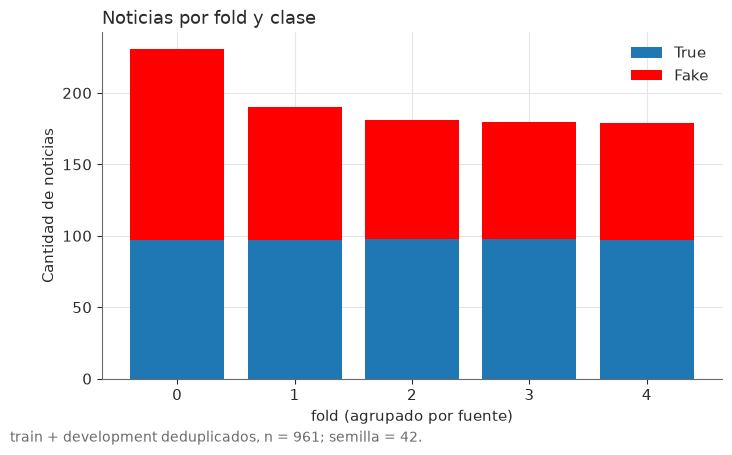

In [18]:
conteo_folds = pd.crosstab(cv['fold_grupo'], cv['Category'])
fig, ax = plt.subplots(figsize = (8, 4.5))
ax.bar(conteo_folds.index, conteo_folds['True'], color = COLORES_CLASE['True'], label = 'True')
ax.bar(conteo_folds.index, conteo_folds['Fake'], bottom = conteo_folds['True'], color = COLORES_CLASE['Fake'], label = 'Fake')
ax.set_xlabel('fold (agrupado por fuente)')
ax.set_ylabel('Cantidad de noticias')
ax.set_title('Noticias por fold y clase')
ax.legend()
fig.text(0.01, -0.03, f'train + development deduplicados, n = {len(cv)}; semilla = {SEMILLA}.', color = TINTA_SUAVE, fontsize = 10)
guardar(fig, '6_1_folds_por_clase')
plt.show()

### 6.3 Verificaciones (Tabla 6.3)

**Tabla 6.3.** Esperado frente a obtenido.

In [19]:
fold_por_fuente = cv.groupby('fuente')['fold_grupo'].nunique()
pct_global = 100 * (cv['Category'] == 'Fake').mean()
checks = pd.DataFrame([
    ('ninguna fuente en dos folds', 0, int((fold_por_fuente > 1).sum())),
    ('folds con % Fake a más de 5 puntos del global', 0, int((composicion['% Fake'] - pct_global).abs().gt(5).sum())),
    ('noticias de test en los folds', 0, int((cv['particion'] == 'test').sum())),
    ('noticias sin fold', 0, int((cv['fold_grupo'] < 0).sum() + (cv['fold_aleatorio'] < 0).sum())),
    ('id_unico repetidos', 0, int(cv['id_unico'].duplicated().sum())),
], columns = ['verificación', 'esperado', 'obtenido'])
checks['resultado'] = np.where(checks['esperado'] == checks['obtenido'], '✅', '❌')
checks

,verificación,esperado,obtenido,resultado
0,ninguna fuente en dos folds,0,0,✅
1,folds con % Fake a más de 5 puntos del global,0,1,❌
2,noticias de test en los folds,0,0,✅
3,noticias sin fold,0,0,✅
4,id_unico repetidos,0,0,✅


El balance del fold 0 depende de la fuente más grande. **Tabla 6.4.** Desviación máxima del % de falsas de un fold respecto al global con 30 semillas distintas (solo diagnóstico; los folds se quedan con `SEMILLA`).

In [20]:
desviaciones = []
for s in range(30):
    pct = [100 * (cv['Category'].iloc[idx] == 'Fake').mean()
           for _, idx in StratifiedGroupKFold(n_splits = N_FOLDS, shuffle = True, random_state = s).split(cv, cv['Category'], groups = cv['fuente'])]
    desviaciones.append(max(abs(np.array(pct) - pct_global)))
pd.Series(desviaciones).describe()[['count', 'min', 'max']].round(1).rename('desviación máxima (puntos)').to_frame()

,desviación máxima (puntos)
count,30.0
min,8.7
max,8.7


**Qué se observa.** Se cumplen 4 de 5 verificaciones: ninguna fuente aparece en dos folds, no hay noticias del test, todas tienen fold y no hay identificadores repetidos. Falla el balance: el fold 0 tiene 58.0 % de falsas contra 49.3 % global, porque contiene a *El Dizque*, con 134 falsas. La Tabla 6.4 muestra que la desviación máxima es 8.7 puntos con las 30 semillas probadas: no depende de la semilla, sino de que el grupo más grande es casi el 14 % del corpus y de una sola clase. Se descartó partir la fuente o cambiar de semilla, porque ninguna opción lo corrige sin romper el agrupamiento. **La F1 de fake por fold variará en parte por la proporción de clases; por eso reportamos media ± sd y la macro-F1 como complementaria.**

### 6.4 Pares verdadera–falsa y folds (Tabla 6.5)

Reconstruimos los pares candidatos con el mismo método del análisis exploratorio (Sección 12.3) y contamos cuántos quedan con sus dos miembros en el mismo fold. **Tabla 6.5.** Pares candidatos según el esquema de folds.

In [21]:
def emparejar(df, umbral):
    '''
    Función que reconstruye pares verdadera–falsa por similitud de titulares (mejor pareja mutua)

    inputs:
    --------
        df (pandas.DataFrame): Noticias con 'titular' y 'Category'
        umbral (float): Coseno mínimo para aceptar el par

    outputs:
    --------
        pandas.DataFrame: Índices posicionales de la falsa y la verdadera de cada par y su coseno
    '''
    vectores = TfidfVectorizer(sublinear_tf = True, stop_words = list(STOPWORDS_ES),
                               token_pattern = r'(?u)\b[^\W\d_]{3,}\b').fit_transform(df['titular'])
    falsas, verdaderas = np.where(df['Category'] == 'Fake')[0], np.where(df['Category'] == 'True')[0]
    sim = cosine_similarity(vectores[falsas], vectores[verdaderas])
    mejor_v, mejor_f = sim.argmax(axis = 1), sim.argmax(axis = 0)
    return pd.DataFrame([(falsas[i], verdaderas[mejor_v[i]], sim[i, mejor_v[i]]) for i in range(len(falsas))
                         if mejor_f[mejor_v[i]] == i and sim[i, mejor_v[i]] >= umbral], columns = ['i_fake', 'i_true', 'coseno'])

pares_cv = emparejar(cv, UMBRAL_PAR)
pd.DataFrame({esquema: {'pares candidatos': len(pares_cv),
                        'pares en el mismo fold': int((cv[esquema].values[pares_cv['i_fake']] == cv[esquema].values[pares_cv['i_true']]).sum())}
              for esquema in ['fold_grupo', 'fold_aleatorio']}).T.assign(
    **{'% en el mismo fold': lambda t: (100 * t['pares en el mismo fold'] / t['pares candidatos']).round(1)})

,pares candidatos,pares en el mismo fold,% en el mismo fold
fold_grupo,122,24,19.7
fold_aleatorio,122,25,20.5


**Qué se observa.** De los 122 pares candidatos reconstruidos en `train` + `development`, 24 (19.7 %) quedan con ambos miembros en el mismo fold agrupado y 25 (20.5 %) en el aleatorio. Ambos valores son lo esperado por azar con 5 folds (1/5 = 20 %): agrupar por fuente no separa ni junta los pares. En el 80 % de los pares, un miembro entrena mientras el otro valida, pero con la clase contraria, así que ver al "gemelo" no ayuda a acertar. **No esperamos optimismo por pares; queda documentado como limitación.**

### 6.5 Guardado de los folds

**Tabla 6.6.** Primeras filas de `resultados/folds.csv`.

In [22]:
folds = cv[['id_unico', 'particion', 'Id', 'fuente', 'Topic', 'Category', 'fold_grupo', 'fold_aleatorio']].assign(semilla = SEMILLA)
guardar_csv(folds, 'folds')
folds.head()

,id_unico,particion,Id,fuente,Topic,Category,fold_grupo,fold_aleatorio,semilla
0,tra_1,train,1,el ruinaversal,Education,Fake,1,4,42
1,tra_2,train,2,hay noticia,Education,Fake,4,4,42
2,tra_3,train,3,el ruinaversal,Education,Fake,1,0,42
3,tra_4,train,4,el universal,Education,True,3,0,42
4,tra_5,train,5,lamula,Education,Fake,2,4,42


<a id="seccion-7"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 7: Formato y guardado</span></div>

> **Qué se hace:** guardamos el corpus preparado en Parquet, separando train + development del test.
>
> **Qué se espera ver:** dos archivos que se leen de vuelta idénticos.

Guardamos el test en un archivo aparte para que los notebooks de modelado no puedan cargarlo por accidente: solo `evaluacion.ipynb` lee `test.parquet`. Las columnas originales se conservan con su nombre; las nuevas tienen nombre propio.

**Tabla 7.1.** Columnas del corpus preparado por rol.

In [23]:
columnas = {'identificación': ['id_unico', 'Id', 'particion', 'version'],
            'etiqueta': ['Category', 'y'],
            'entrada (texto)': ['titular', 'texto', 'titular_sin_medio', 'texto_sin_medio'],
            'entrada (rasgos densos)': uf.RASGOS_ESTILO,
            'grupo y análisis': ['fuente', 'dominio', 'Topic', 'Source', 'Link'] + banderas,
            'originales (referencia)': ['Headline', 'Text']}
prep['y'] = (prep['Category'] == 'Fake').astype(int)
orden = [c for cs in columnas.values() for c in cs]
corpus_cv = prep.loc[prep['particion'] != 'test', orden].merge(folds[['id_unico', 'fold_grupo', 'fold_aleatorio']], on = 'id_unico')
corpus_test = prep.loc[prep['particion'] == 'test', orden].reset_index(drop = True)
corpus_cv.to_parquet(os.path.join(uf.RUTA_PROCESADOS, 'corpus.parquet'), index = False)
corpus_test.to_parquet(os.path.join(uf.RUTA_PROCESADOS, 'test.parquet'), index = False)
pd.DataFrame({'rol': list(columnas), 'columnas': [', '.join(c) for c in columnas.values()]})

,rol,columnas
0,identificación,"id_unico, Id, particion, version"
1,etiqueta,"Category, y"
2,entrada (texto),"titular, texto, titular_sin_medio, texto_sin_m..."
3,entrada (rasgos densos),"est_log_palabras, est_palabras_por_oracion, es..."
4,grupo y análisis,"fuente, dominio, Topic, Source, Link, sin_titu..."
5,originales (referencia),"Headline, Text"


**Tabla 7.2.** Verificación de lectura. Se comparan valores, no tipos: Parquet devuelve las columnas de texto con el tipo `str` de pandas 3 en lugar de `object`.

In [24]:
def iguales(a, b):
    '''
    Función que compara dos tablas por valores, ignorando diferencias de tipo de columna

    inputs:
    --------
        a (pandas.DataFrame): Primera tabla
        b (pandas.DataFrame): Segunda tabla

    outputs:
    --------
        bool: True si tienen las mismas columnas y valores
    '''
    try:
        pd.testing.assert_frame_equal(a.reset_index(drop = True), b.reset_index(drop = True), check_dtype = False)
        return True
    except AssertionError:
        return False

releido_cv = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'corpus.parquet'))
releido_test = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'test.parquet'))
pd.DataFrame({'archivo': ['corpus.parquet', 'test.parquet'], 'filas': [len(releido_cv), len(releido_test)],
              'columnas': [releido_cv.shape[1], releido_test.shape[1]],
              'mismos valores que lo guardado': ['✅' if iguales(releido_cv, corpus_cv) else '❌', '✅' if iguales(releido_test, corpus_test) else '❌']})

,archivo,filas,columnas,mismos valores que lo guardado
0,corpus.parquet,961,33,✅
1,test.parquet,572,31,✅


<a id="seccion-8"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 8: Perfilado antes y después</span></div>

> **Qué se hace:** volvemos a medir los indicadores de calidad sobre el corpus preparado y los comparamos con el original.
>
> **Qué se espera ver:** cero duplicados entre particiones, formato común entre versiones y proporciones de clase casi iguales.

**Tabla 8.1.** Indicadores antes (homogeneizado, sin preparar) y después de la preparación.

In [25]:
def perfil(df, col_titular, col_texto):
    '''
    Función que mide los indicadores de calidad de un corpus

    inputs:
    --------
        df (pandas.DataFrame): Corpus con 'particion', 'version' y 'Category'
        col_titular (str): Columna del titular
        col_texto (str): Columna del texto

    outputs:
    --------
        pandas.Series: Indicadores de tamaño, balance, duplicados y formato
    '''
    tit, txt = df[col_titular].fillna(''), df[col_texto]
    comp = (tit + ' ' + txt).str.replace(r'\*[A-Z]+\*', ' ', regex = True)
    sim = cosine_similarity(TfidfVectorizer(sublinear_tf = True).fit_transform(comp))
    i, j = np.where(np.triu(sim, k = 1) >= UMBRAL_CASI_DUPLICADO)
    part = df['particion'].values
    v2 = df['version'] == '2.0'
    return pd.Series({
        'noticias train + development': int((df['particion'] != 'test').sum()), 'noticias test': int(v2.sum()),
        '% Fake train + development': round(100 * (df.loc[df['particion'] != 'test', 'Category'] == 'Fake').mean(), 1),
        'pares casi duplicados (total)': len(i),
        'pares casi duplicados entre particiones': int((part[i] != part[j]).sum()),
        'textos vacíos': int(txt.str.strip().eq('').sum()),
        'textos con espacios repetidos': int(txt.str.contains(r'[ \t]{2,}').sum()),
        '% textos v1.0 que empiezan con su titular': round(100 * np.mean([x.lower().startswith(t.strip().lower()) and t.strip() != ''
                                                                           for t, x in zip(tit[~v2], txt[~v2])]), 1),
        '% textos v2.0 con *NUMBER*': round(100 * txt[v2].str.contains(r'\*NUMBER\*').mean(), 1),
        'mediana de palabras': txt.str.split().str.len().median()})

pd.DataFrame({'antes': perfil(crudo, 'Headline', 'Text'), 'después': perfil(prep, 'titular', 'texto')})

,antes,después
noticias train + development,971.0,961.0
noticias test,572.0,572.0
% Fake train + development,49.4,49.3
pares casi duplicados (total),11.0,1.0
pares casi duplicados entre particiones,9.0,0.0
textos vacíos,0.0,0.0
textos con espacios repetidos,99.0,0.0
% textos v1.0 que empiezan con su titular,97.1,0.4
% textos v2.0 con *NUMBER*,0.0,86.5
mediana de palabras,338.0,328.0


**Qué se observa.** Después de preparar, `train` + `development` tiene 961 noticias (antes 971) con 49.3 % de falsas (antes 49.4 %), y el test sigue con 572. Los pares casi duplicados bajan de 11 a 1 (el par 109 / 353 del test, con clases distintas) y los que cruzan particiones de 9 a 0. Los textos con espacios repetidos bajan de 99 a 0. Los textos de la 1.0 que empiezan con su titular bajan de 97.1 % a 0.4 %; el 0.4 % restante son titulares que no coinciden exactamente con el inicio del texto. El 86.5 % de los textos de la 2.0 tiene ahora marcas `*NUMBER*` (antes 0 %). La mediana de palabras baja de 338 a 328 por quitar el titular repetido. **La preparación eliminó la fuga y las diferencias de formato sin cambiar el balance de clases.**

<a id="seccion-9"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 9: Bitácora de calidad</span></div>

> **Qué se hace:** registramos cada hallazgo con su dimensión, cómo se detectó, la acción y los textos afectados.
>
> **Qué se espera ver:** una fila por acción, con los conteos calculados en este notebook.

**Tabla 9.1.** Bitácora de calidad.

In [26]:
bitacora = pd.DataFrame([
    ('Casi duplicados train ↔ test', 'Unicidad', 'Coseno TF-IDF ≥ 0.8', 'EDA 12.1; Tabla 2.1', 'Eliminar la copia de train',
     int(((crudo['particion'] == 'train') & crudo['id_unico'].isin(eliminados)).sum())),
    ('Casi duplicados train ↔ development y dentro de development', 'Unicidad', 'Coseno TF-IDF ≥ 0.8', 'Tabla 2.1', 'Eliminar la copia de development',
     int(((crudo['particion'] == 'development') & crudo['id_unico'].isin(eliminados)).sum())),
    ('Espacios repetidos y espacios duros', 'Consistencia', 'Expresión regular', 'EDA 13.1', 'Normalizar espacios', int(cambios['3.1 espacios'].sum())),
    ('Titular repetido al inicio del texto (v1.0)', 'Consistencia', 'Comparación de prefijo', 'EDA 5.5', 'Quitar el prefijo', int(cambios['3.2 titular repetido al inicio'].sum())),
    ('Números y URLs sin anonimizar (v2.0)', 'Consistencia', 'Expresión regular', 'EDA 5.5', 'Reemplazar por *NUMBER* y *URL*', int(cambios['3.3 anonimización (números y URLs)'].sum())),
    ('Titular faltante solo en falsas (test)', 'Completitud', 'Nulos por clase', 'EDA 5.2', 'Cadena vacía + bandera de análisis', int(cambios['3.4 titular vacío → cadena vacía'].sum())),
    ('Nombre o dominio del medio en el texto', 'Exactitud (atajo)', 'Léxico de fuentes de train', 'EDA 14; Tabla 4.3', 'Versión con los nombres de medio borrados', int(prep['menciona_medio'].sum())),
    ('Enlace "Perma" y fuente que delatan la clase', 'Validez', 'Reglas de dominio', 'EDA 5.6 y 8', 'Excluir Link y Source de la entrada', len(prep)),
    ('Textos largos atípicos', 'Exactitud', 'IQR por versión', 'EDA 9.4', 'Conservar (legítimos)', 0),
], columns = ['Hallazgo', 'Dimensión', 'Detección', 'Evidencia', 'Acción', 'Textos afectados'])
guardar_csv(bitacora, 'preparacion_bitacora')
bitacora

,Hallazgo,Dimensión,Detección,Evidencia,Acción,Textos afectados
0,Casi duplicados train ↔ test,Unicidad,Coseno TF-IDF ≥ 0.8,EDA 12.1; Tabla 2.1,Eliminar la copia de train,4
1,Casi duplicados train ↔ development y dentro d...,Unicidad,Coseno TF-IDF ≥ 0.8,Tabla 2.1,Eliminar la copia de development,6
2,Espacios repetidos y espacios duros,Consistencia,Expresión regular,EDA 13.1,Normalizar espacios,338
3,Titular repetido al inicio del texto (v1.0),Consistencia,Comparación de prefijo,EDA 5.5,Quitar el prefijo,937
4,Números y URLs sin anonimizar (v2.0),Consistencia,Expresión regular,EDA 5.5,Reemplazar por *NUMBER* y *URL*,499
5,Titular faltante solo en falsas (test),Completitud,Nulos por clase,EDA 5.2,Cadena vacía + bandera de análisis,72
6,Nombre o dominio del medio en el texto,Exactitud (atajo),Léxico de fuentes de train,EDA 14; Tabla 4.3,Versión con los nombres de medio borrados,216
7,"Enlace ""Perma"" y fuente que delatan la clase",Validez,Reglas de dominio,EDA 5.6 y 8,Excluir Link y Source de la entrada,1533
8,Textos largos atípicos,Exactitud,IQR por versión,EDA 9.4,Conservar (legítimos),0


**Qué se observa.** La bitácora registra 9 hallazgos. Las acciones que más textos tocan son quitar el titular repetido (937), anonimizar números y URLs (499) y normalizar espacios (338). La eliminación de duplicados afecta a 10 noticias (4 de `train` y 6 de `development`). Los textos largos atípicos se conservan (0 afectados). **Cada cambio al corpus tiene un hallazgo del EDA que lo justifica y un conteo verificable.**

<a id="conclusiones"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

<a id="seccion-10"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 10: Resumen por sección</span></div>

> **Qué se hace:** reunimos qué se hizo y qué salió de cada sección.
>
> **Qué se espera ver:** el estado del corpus que reciben los notebooks de modelado.

**Tabla 10.1.** Resumen por sección.

| Sección | Qué se hizo | Hallazgo principal | Salidas |
|:--|:--|:--|:--|
| 1. Selección | Roles de las columnas, `id_unico` | Solo `Headline` y `Text` entran al modelo; los `Id` se repiten 867 veces | Tabla 1.1 |
| 2. Duplicados | Coseno TF-IDF ≥ 0.8 y regla de eliminación | Se eliminan 10 noticias (4 copias de noticias del test); quedan 961 | Tabla 2.2 |
| 3. Normalización | Espacios, titular repetido, anonimización, titular vacío | 5 de 5 verificaciones ✅; formato común entre versiones | Tablas 3.1 y 3.2 |
| 4. Medio | Léxico de 222 nombres; versión con los nombres borrados | Menciones de medios en el 21.6 % de las verdaderas contra el 8.2 % de las falsas de la 1.0 | `data/processed/lexico_medios.csv` |
| 5. Rasgos y banderas | 10 rasgos de estilo y 4 banderas | Solo `est_numeros` mantiene su dirección entre versiones | Tabla 5.2 |
| 6. Folds | `StratifiedGroupKFold` por fuente, semilla 42 | Ninguna fuente en dos folds; el fold 0 tiene 58.0 % de falsas (estructural) | `resultados/folds.csv`, Figura 6.1 |
| 7. Guardado | Parquet separado para el test | Lectura con los mismos valores ✅ | `data/processed/corpus.parquet`, `test.parquet` |
| 8. Perfilado | Antes frente a después | 0 duplicados entre particiones; balance sin cambios | Tabla 8.1 |
| 9. Bitácora | Hallazgo, acción y textos afectados | 9 acciones documentadas | `resultados/preparacion_bitacora.csv` |

<a id="seccion-11"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 11: Implicaciones para el modelado</span></div>

> **Qué se hace:** listamos lo que los notebooks de modelado deben respetar.
>
> **Qué se espera ver:** reglas concretas para `modelos_lineales.ipynb` y `modelo_arboles.ipynb`.

* **Leer siempre de disco.** `data/processed/corpus.parquet` y `resultados/folds.csv` (columna `fold_grupo`); nadie vuelve a limpiar ni a partir. Los notebooks de modelado **no** leen `test.parquet`.
* **Entradas permitidas.** `titular` y `texto`, o sus versiones `_sin_medio`, y las columnas `est_*`. Nunca `fuente`, `dominio`, `Topic`, `Source`, `Link` ni las banderas.
* **Todo lo que aprende va en un `Pipeline`.** Vocabulario, IDF, `min_df`, χ² y escalado se ajustan dentro de cada fold.
* **Comparaciones obligatorias en CV.** (1) `texto` frente a `texto_sin_medio`; (2) titular y texto en bloques separados frente a concatenados; (3) `fold_grupo` frente a `fold_aleatorio`, solo como diagnóstico.
* **Métricas por fold.** F1 de fake (principal), F1 de true, macro-F1 y exactitud con `uf.metricas`, reportadas como media ± sd; el fold 0 tiene más falsas que los demás.
* **Formato de los CSV de CV.** `modelo | representación | hiperparámetros | fold | F1_fake | F1_macro | accuracy`.
* **Rasgos de estilo.** Esperamos que ayuden poco o perjudiquen en el test (solo `est_numeros` es estable); el modelo de árboles debe confirmarlo en CV.

<a id="seccion-12"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 12: Referencias</span></div>

> **Qué se hace:** fuentes citadas.
>
> **Qué se espera ver:** referencias completas.

1. Gómez-Adorno, H., Posadas-Durán, J. P., Bel Enguix, G. y Porto Capetillo, C. (2021). Overview of FakeDeS at IberLEF 2021: Fake News Detection in Spanish Shared Task. *Procesamiento del Lenguaje Natural*, 67, 223–231.
2. Gamallo, P. (2021). CiTIUS at FakeDeS 2021: A Hybrid Strategy for Fake News Detection. *CEUR-WS* Vol. 2943, 609–614.
3. Kiesel, J. et al. (2019). SemEval-2019 Task 4: Hyperpartisan News Detection. En *Proceedings of SemEval-2019*. https://aclanthology.org/S19-2145/
4. Grave, I. (agosto de 2026). Minería de Datos: primera sesión. Materiales de la asignatura Minería de Datos.
5. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830 (`StratifiedGroupKFold`, `Pipeline`).

> Corpus: **The Spanish Fake News Corpus** (versiones 1.0 y 2.0), [jpposadas/FakeNewsCorpusSpanish](https://github.com/jpposadas/FakeNewsCorpusSpanish), licencia CC BY 4.0. Los archivos `.xlsx` no se modifican; los derivados se guardan en `data/processed/`.